# 赛道 B：时序行为聚类与关联规则挖掘

大作业《基于混合式教学行为数据的学生学习风险挖掘》，选做赛道 B。

流程：数据理解与核查 → 主表清洗 → 周度时序特征工程 → K-Means 聚类与学生画像 → Apriori 关联规则 → 结果核验。

数据：`student_main_data.csv`（主表，含挂科标签）和 `student_weekly_behavior.csv`（16 周时序表），按 `student_id` 关联。原始 CSV 不做任何修改，所有处理都在代码里完成。

In [1]:
import glob
import os
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

if os.path.exists('/content'):
    os.system('apt-get -qq install -y fonts-noto-cjk > /dev/null')
    font_path = glob.glob('/usr/share/fonts/**/NotoSansCJK*-Regular.ttc', recursive=True)[0]
    fm.fontManager.addfont(font_path)
    plt.rcParams['font.family'] = fm.FontProperties(fname=font_path).get_name()
else:
    plt.rcParams['font.family'] = ['PingFang SC', 'Heiti SC', 'Arial Unicode MS', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

In [2]:
import warnings
import numpy as np
import pandas as pd
warnings.filterwarnings('ignore')

DATA_DIR = os.environ.get('STUDENT_DATA_DIR', 'data')
main = pd.read_csv(f'{DATA_DIR}/student_main_data.csv')
weekly = pd.read_csv(f'{DATA_DIR}/student_weekly_behavior.csv')
print('主表', main.shape, '周表', weekly.shape)

主表 (1220, 15) 周表 (19200, 6)


## 1. 数据理解与核查

### 1.1 主表的数据缺陷
任务书说明主表内置了缺失值、刷课样本、重复行、极端异常值和多重共线性，这里逐一核对。

In [3]:
num_cols = [c for c in main.columns if c not in ('student_id', 'fail_label')]
checks = {
    '总行数': len(main),
    '完全重复的行': int(main.duplicated().sum()),
    '学生编号重复': int(main['student_id'].duplicated().sum()),
    '含缺失值的行': int(main.isna().any(axis=1).sum()),
    'knowledge_master_rate 缺失': int(main['knowledge_master_rate'].isna().sum()),
    'offline_performance 缺失': int(main['offline_performance'].isna().sum()),
    '线上学时为负': int((main['online_study_hour'] < 0).sum()),
    '掌握率大于 1': int((main['knowledge_master_rate'] > 1).sum()),
    '刷课嫌疑（学时>90 且有效率<0.15）': int(((main['online_study_hour'] > 90) & (main['online_valid_rate'] < 0.15)).sum()),
}
pd.Series(checks).to_frame('数量')

,数量
总行数,1220
完全重复的行,20
学生编号重复,20
含缺失值的行,64
knowledge_master_rate 缺失,31
offline_performance 缺失,33
线上学时为负,4
掌握率大于 1,4
刷课嫌疑（学时>90 且有效率<0.15）,69


In [4]:
dedup = main.drop_duplicates()
corr = dedup[num_cols].corr()
print(f"chapter_pass_rate 与 knowledge_master_rate 的相关系数：{corr.loc['chapter_pass_rate', 'knowledge_master_rate']:.3f}")
print(f"live_attend_num 与 live_absent_num 的相关系数：{corr.loc['live_attend_num', 'live_absent_num']:.3f}（两者相加恒为 16）")

chapter_pass_rate 与 knowledge_master_rate 的相关系数：0.982
live_attend_num 与 live_absent_num 的相关系数：-1.000（两者相加恒为 16）


### 1.2 标签核查

任务书说挂科样本约占 22%，这里实际统计一下，并看几个关键指标在挂科组和未挂科组的均值。

In [5]:
label_check = pd.DataFrame({
    '挂科组均值': dedup[dedup.fail_label == 1][['knowledge_master_rate', 'mid_score', 'homework_online_score', 'weak_point_num', 'live_absent_num']].mean(),
    '未挂科组均值': dedup[dedup.fail_label == 0][['knowledge_master_rate', 'mid_score', 'homework_online_score', 'weak_point_num', 'live_absent_num']].mean(),
})
print(f"挂科率：{dedup.fail_label.mean():.1%}（{dedup.fail_label.sum()} / {len(dedup)}）")
label_check.round(3)

挂科率：65.0%（780 / 1200）


,挂科组均值,未挂科组均值
knowledge_master_rate,0.656,0.422
mid_score,63.076,55.904
homework_online_score,62.185,50.397
weak_point_num,3.973,4.417
live_absent_num,7.099,9.107


挂科率约 65%，不是任务书说的 22%；而且挂科组的掌握率、期中成绩、作业分反而**更高**，缺勤和薄弱点反而更少。

对照任务书附带的生成脚本：挂科标签由 `p = 1 / (1 + exp(-logit))`、`fail_label = (rand < p)` 生成，而 logit 里掌握率、成绩、作业分的系数都是正的，所以这些指标越好，`p` 越大，越容易被标成"挂科"。这说明数据生成时标签方向很可能写反了。后面的分析如实保留这一点，不擅自翻转标签。

### 1.3 周度时序表

In [6]:
wcols = ['weekly_video_hour', 'weekly_quiz_score', 'weekly_login_num', 'weekly_interact_num']
wnames = {'weekly_video_hour': '视频时长', 'weekly_quiz_score': '小测分数', 'weekly_login_num': '登录次数', 'weekly_interact_num': '互动次数'}
print('缺失值', int(weekly.isna().sum().sum()), '，重复行', int(weekly.duplicated().sum()),
      '，学生数', weekly.student_id.nunique(), '，每人周数', weekly.groupby('student_id').size().unique())
weekly[wcols].describe().round(2)

缺失值 0 ，重复行 0 ，学生数 1200 ，每人周数 [16]


,weekly_video_hour,weekly_quiz_score,weekly_login_num,weekly_interact_num
count,19200.00,19200.00,19200.00,19200.00
mean,4.16,62.05,4.23,2.58
std,2.15,18.81,2.68,1.98
min,0.00,1.88,0.00,0.00
25%,2.33,48.99,2.00,1.00
50%,3.98,62.85,4.00,2.00
75%,6.00,77.35,6.00,4.00
max,8.91,100.00,13.00,10.00


## 2. 主表清洗

赛道 B 的核心数据是周表，主表主要提供挂科标签，另在第 5.3 节作为补充特征。清洗规则：
1. 删除 20 条完全重复的行；
2. 极端异常值（学时为负、掌握率大于 1）视为错误记录，置为缺失；
3. 缺失值用中位数填补（这里是无监督分析，不涉及训练 / 测试划分）；
4. 刷课挂机样本不删除，单独标记为一个特征，供关联规则使用；
5. `chapter_pass_rate` 与 `knowledge_master_rate` 高度相关，只保留后者。

In [7]:
clean = main.drop_duplicates().copy()
clean.loc[clean['online_study_hour'] < 0, 'online_study_hour'] = np.nan
clean.loc[clean['knowledge_master_rate'] > 1, 'knowledge_master_rate'] = np.nan
clean['brush_flag'] = (clean['online_study_hour'] > 90) & (clean['online_valid_rate'] < 0.15)
for c in ['online_study_hour', 'knowledge_master_rate', 'offline_performance']:
    clean[c] = clean[c].fillna(clean[c].median())
clean = clean.drop(columns=['chapter_pass_rate']).set_index('student_id')
print('清洗后', clean.shape, '，剩余缺失', int(clean.isna().sum().sum()), '，刷课标记', int(clean.brush_flag.sum()))

清洗后 (1200, 14) ，剩余缺失 0 ，刷课标记 68


## 3. 周度时序特征工程

对每个学生的 4 项周指标分别构造：
- 统计特征：16 周均值、标准差；
- 趋势特征：对周次做线性回归的斜率；
- 阶段特征：前期（第 1~5 周）、中期（第 6~11 周）、后期（第 12~16 周）均值，以及"后期均值 − 前期均值"；
- 断崖标记：视频时长和小测分数的后期均值都不到前期的一半。

In [8]:
def student_features(g):
    g = g.sort_values('week')
    r = {}
    for c in wcols:
        s = g[c].to_numpy()
        n = wnames[c]
        r[f'{n}_均值'] = s.mean()
        r[f'{n}_标准差'] = s.std(ddof=1)
        r[f'{n}_斜率'] = np.polyfit(np.arange(1, 17), s, 1)[0]
        r[f'{n}_前期'] = s[:5].mean()
        r[f'{n}_中期'] = s[5:11].mean()
        r[f'{n}_后期'] = s[11:].mean()
        r[f'{n}_变化'] = s[11:].mean() - s[:5].mean()
    return pd.Series(r)

feat = weekly.groupby('student_id').apply(student_features)
feat['断崖'] = (feat['视频时长_后期'] < 0.5 * feat['视频时长_前期']) & (feat['小测分数_后期'] < 0.5 * feat['小测分数_前期'])
feat = feat.join(clean['fail_label'])
print(f"构造了 {feat.shape[1] - 2} 个时序特征；断崖式下降学生 {feat['断崖'].sum()} 人（{feat['断崖'].mean():.1%}）")
feat.filter(like='视频时长').describe().round(2)

构造了 28 个时序特征；断崖式下降学生 189 人（15.8%）


,视频时长_均值,视频时长_标准差,视频时长_斜率,视频时长_前期,视频时长_中期,视频时长_后期,视频时长_变化
count,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00
mean,4.16,0.53,-0.04,4.37,4.17,3.94,-0.43
std,2.06,0.38,0.10,2.04,2.06,2.22,1.13
min,0.54,0.15,-0.46,0.64,0.43,0.11,-5.12
25%,2.42,0.35,-0.03,2.57,2.41,2.01,-0.30
50%,3.97,0.41,-0.00,4.36,3.97,3.57,-0.05
75%,5.95,0.48,0.01,6.15,5.92,5.94,0.13
max,8.13,2.21,0.07,8.32,8.14,8.21,0.77


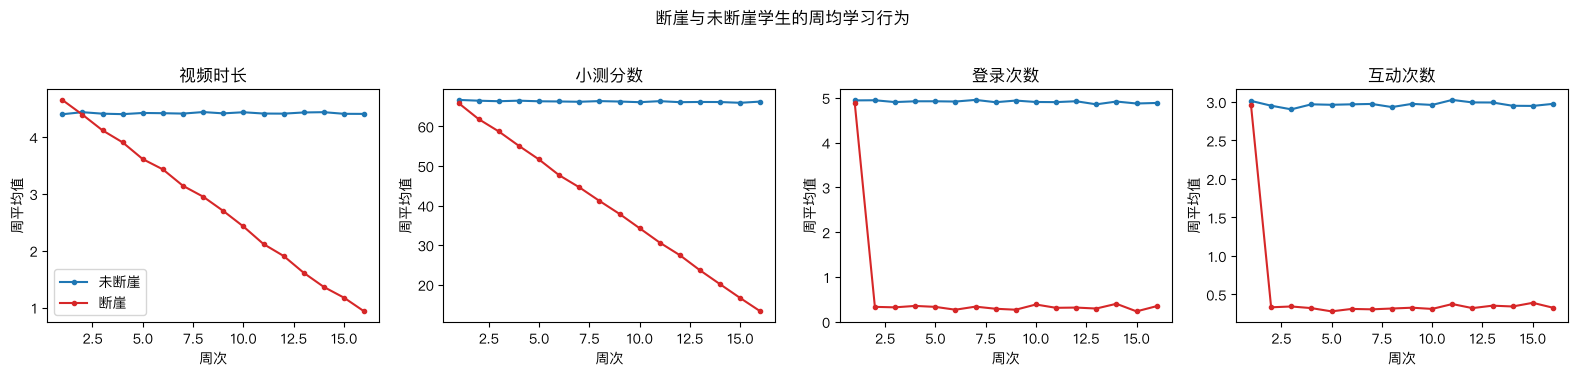

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
wk = weekly.merge(feat[['断崖']], left_on='student_id', right_index=True)
for ax, c in zip(axes, wcols):
    for flag, label, color in [(False, '未断崖', 'C0'), (True, '断崖', 'C3')]:
        s = wk[wk['断崖'] == flag].groupby('week')[c].mean()
        ax.plot(s.index, s.values, marker='o', ms=3, label=label, color=color)
    ax.set_title(wnames[c])
    ax.set_xlabel('周次')
    ax.set_ylabel('周平均值')
axes[0].legend()
fig.suptitle('断崖与未断崖学生的周均学习行为', y=1.03)
plt.tight_layout()
plt.show()

In [10]:
print('两名断崖学生的每周登录次数：')
weekly[weekly.student_id.isin(feat[feat['断崖']].index[:2])].pivot(index='student_id', columns='week', values='weekly_login_num')

两名断崖学生的每周登录次数：


week,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
student_id,,,,,,,,,,,,,,,,
2,6,0,0,0,0,1,0,1,0,1,0,0,0,1,1,0
10,6,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0


断崖学生的视频时长和小测分数是逐周线性下降的；登录和互动次数则在第 2 周就几乎降到 0~1 次。原因可能是生成脚本里 `decay.astype(int)` 把 0.2~0.95 的衰减系数都截断成 0，只有第 1 周保留了原值。

## 4. K-Means 聚类与学生画像

### 4.1 选择 K
聚类特征：4 项指标的均值、标准差、斜率、后期−前期变化，共 16 个，先标准化。分别用肘部法则（簇内平方和）和轮廓系数选 K。

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_cols = [c for c in feat.columns if c.endswith(('_均值', '_标准差', '_斜率', '_变化'))]
Xs = StandardScaler().fit_transform(feat[cluster_cols])
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(Xs)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Xs, km.labels_))
pd.DataFrame({'K': list(ks), '簇内平方和': np.round(inertia), '轮廓系数': np.round(sil, 3)}).set_index('K')

,簇内平方和,轮廓系数
K,,
2,10353.0,0.547
3,9245.0,0.174
4,8561.0,0.151
5,8029.0,0.133
6,7535.0,0.132
7,7148.0,0.138
8,6758.0,0.135


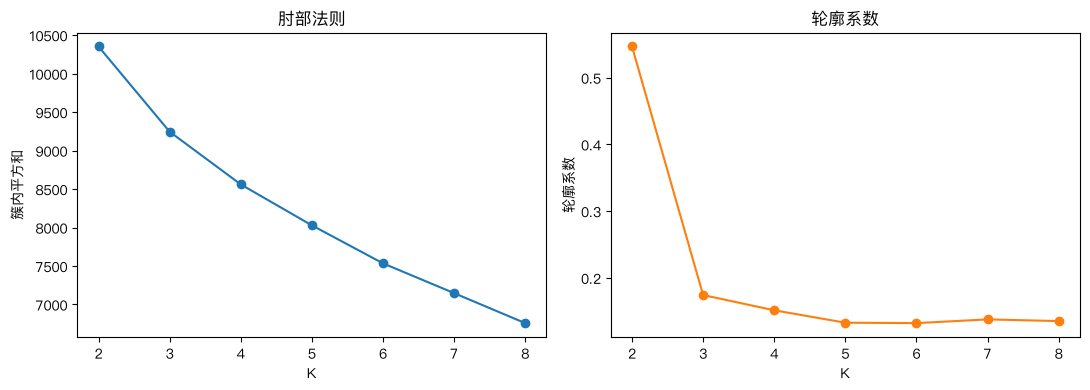

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(list(ks), inertia, marker='o')
axes[0].set_xlabel('K')
axes[0].set_ylabel('簇内平方和')
axes[0].set_title('肘部法则')
axes[1].plot(list(ks), sil, marker='o', color='C1')
axes[1].set_xlabel('K')
axes[1].set_ylabel('轮廓系数')
axes[1].set_title('轮廓系数')
plt.tight_layout()
plt.show()

轮廓系数在 K=2 时明显最高，其余 K 都很低；肘部曲线没有明显拐点。因此主方案取 K=2。任务书提到"稳定型、逐步下滑型、突击型"三类画像，这里另外给出 K=3 的结果作为补充，用来观察稳定组内部的差异，但它的轮廓系数低得多，划分并不清晰。

In [13]:
from scipy.stats import chi2_contingency

def profile(k):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(Xs)
    lab = pd.Series(km.labels_, index=feat.index, name='簇')
    show = ['视频时长_均值', '视频时长_变化', '小测分数_均值', '小测分数_变化', '登录次数_均值', '互动次数_均值']
    tab = feat[show].groupby(lab).mean()
    tab.insert(0, '人数', lab.value_counts().sort_index())
    tab['断崖占比'] = feat['断崖'].groupby(lab).mean()
    tab['挂科率'] = feat['fail_label'].groupby(lab).mean()
    chi2, p, _, _ = chi2_contingency(pd.crosstab(lab, feat['fail_label']))
    return lab, tab, p

lab2, tab2, p2 = profile(2)
print(f'K=2，各簇挂科率差异的卡方检验 p = {p2:.3f}')
tab2.round(3)

K=2，各簇挂科率差异的卡方检验 p = 0.693


,人数,视频时长_均值,视频时长_变化,小测分数_均值,小测分数_变化,登录次数_均值,互动次数_均值,断崖占比,挂科率
簇,,,,,,,,,
0,194,2.727,-2.676,39.470,-38.444,0.611,0.495,0.964,0.665
1,1006,4.438,0.006,66.403,-0.145,4.933,2.981,0.002,0.647


In [14]:
lab3, tab3, p3 = profile(3)
print(f'K=3，各簇挂科率差异的卡方检验 p = {p3:.3f}')
tab3.round(3)

K=3，各簇挂科率差异的卡方检验 p = 0.516


,人数,视频时长_均值,视频时长_变化,小测分数_均值,小测分数_变化,登录次数_均值,互动次数_均值,断崖占比,挂科率
簇,,,,,,,,,
0,194,2.727,-2.676,39.470,-38.444,0.611,0.495,0.964,0.665
1,524,4.774,0.013,68.005,-0.031,5.003,3.042,0.000,0.662
2,482,4.072,-0.002,64.662,-0.268,4.856,2.916,0.004,0.631


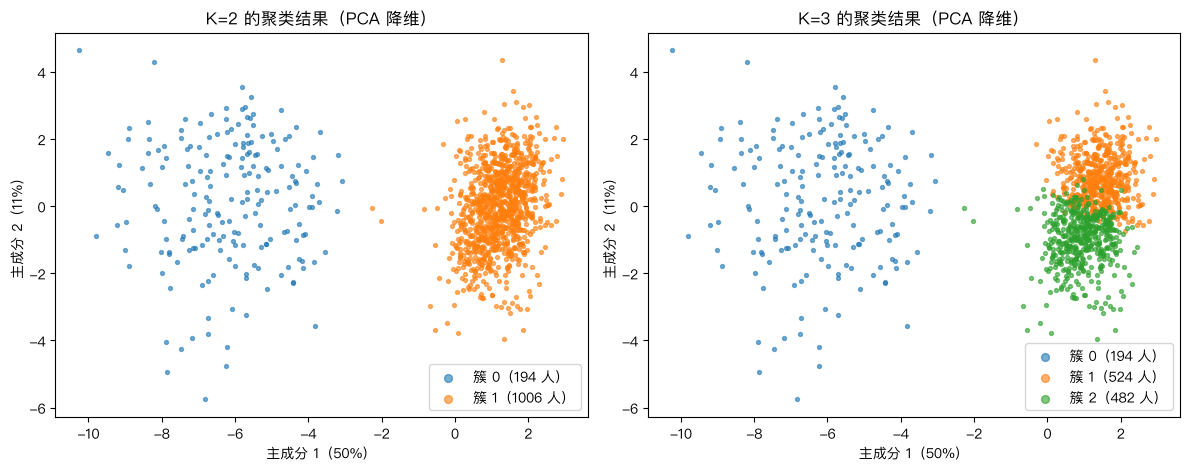

In [15]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42).fit(Xs)
Z = pca.transform(Xs)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, lab, k in [(axes[0], lab2, 2), (axes[1], lab3, 3)]:
    for c in sorted(lab.unique()):
        idx = (lab == c).to_numpy()
        ax.scatter(Z[idx, 0], Z[idx, 1], s=8, alpha=0.6, label=f'簇 {c}（{idx.sum()} 人）')
    ax.set_xlabel(f'主成分 1（{pca.explained_variance_ratio_[0]:.0%}）')
    ax.set_ylabel(f'主成分 2（{pca.explained_variance_ratio_[1]:.0%}）')
    ax.set_title(f'K={k} 的聚类结果（PCA 降维）')
    ax.legend(markerscale=2)
plt.tight_layout()
plt.show()

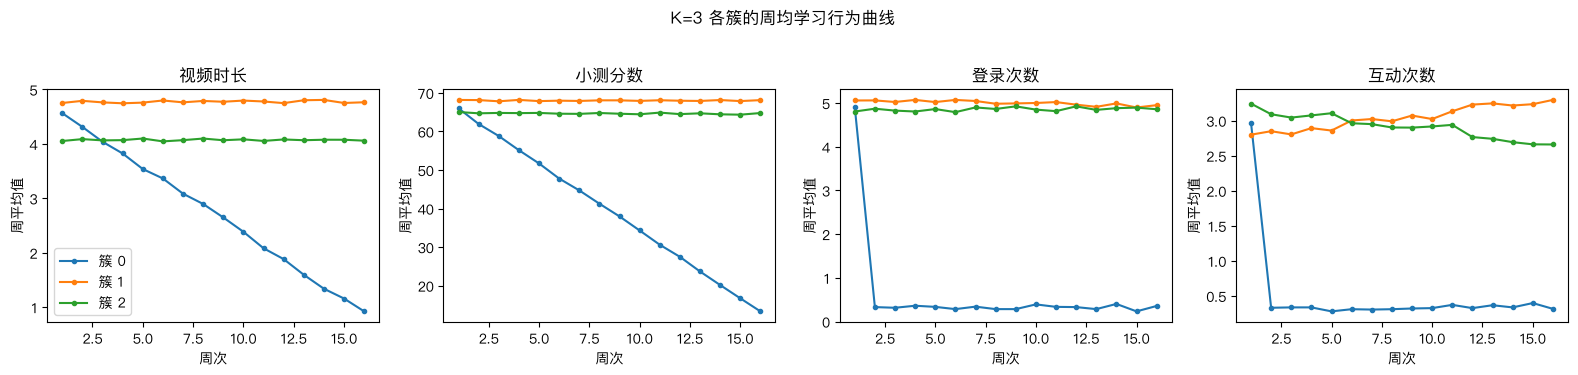

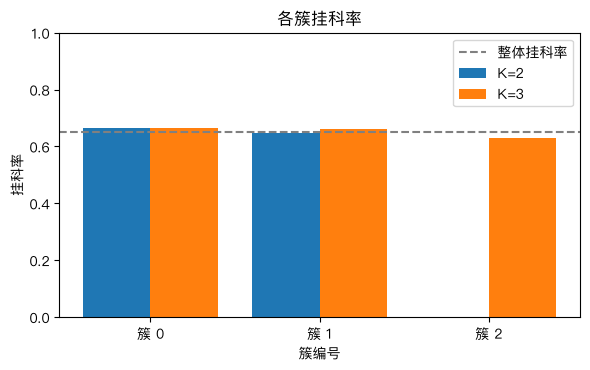

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
wk3 = weekly.merge(lab3.rename('簇'), left_on='student_id', right_index=True)
for ax, c in zip(axes, wcols):
    for cl in sorted(lab3.unique()):
        s = wk3[wk3['簇'] == cl].groupby('week')[c].mean()
        ax.plot(s.index, s.values, marker='o', ms=3, label=f'簇 {cl}')
    ax.set_title(wnames[c])
    ax.set_xlabel('周次')
    ax.set_ylabel('周平均值')
axes[0].legend()
fig.suptitle('K=3 各簇的周均学习行为曲线', y=1.03)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 3.8))
rates = pd.DataFrame({'K=2': tab2['挂科率'], 'K=3': tab3['挂科率']})
x = np.arange(3)
ax.bar(x[:2] - 0.2, tab2['挂科率'].values, 0.4, label='K=2')
ax.bar(x + 0.2, tab3['挂科率'].values, 0.4, label='K=3')
ax.axhline(feat['fail_label'].mean(), color='gray', ls='--', label='整体挂科率')
ax.set_xticks(x)
ax.set_xticklabels(['簇 0', '簇 1', '簇 2'])
ax.set_xlabel('簇编号')
ax.set_ylabel('挂科率')
ax.set_ylim(0, 1)
ax.set_title('各簇挂科率')
ax.legend()
plt.tight_layout()
plt.show()

## 5. Apriori 关联规则

### 5.1 离散化与事务数据集
把时序特征分箱成"低 / 中 / 高"（三分位数）或"骤降 / 平稳"，每个学生的分箱结果加上"挂科 / 不挂科"构成一条事务。

In [17]:
from mlxtend.frequent_patterns import apriori, association_rules

def tertile(s, name):
    return pd.qcut(s.rank(method='first'), 3, labels=[f'{name}低', f'{name}中', f'{name}高']).astype(str)

items = pd.DataFrame(index=feat.index)
for n in ['视频时长', '小测分数', '登录次数', '互动次数']:
    items[n] = tertile(feat[f'{n}_均值'], n)
items['视频趋势'] = np.where(feat['视频时长_变化'] < feat['视频时长_变化'].quantile(0.15), '视频后期骤降', '视频平稳')
items['小测趋势'] = np.where(feat['小测分数_变化'] < feat['小测分数_变化'].quantile(0.15), '小测后期骤降', '小测平稳')
items['结果'] = np.where(feat['fail_label'] == 1, '挂科', '不挂科')
onehot = pd.get_dummies(items, prefix='', prefix_sep='').astype(bool)
print('事务数', len(onehot), '，项数', onehot.shape[1])
onehot.head(3)

事务数 1200 ，项数 18


,视频时长中,视频时长低,视频时长高,小测分数中,小测分数低,小测分数高,登录次数中,登录次数低,登录次数高,互动次数中,互动次数低,互动次数高,视频后期骤降,视频平稳,小测后期骤降,小测平稳,不挂科,挂科
student_id,,,,,,,,,,,,,,,,,,
1,False,True,False,True,False,False,True,False,False,True,False,False,False,True,False,True,True,False
2,False,True,False,False,True,False,False,True,False,False,True,False,False,True,True,False,False,True
3,True,False,False,True,False,False,False,True,False,False,False,True,False,True,False,True,False,True


In [18]:
MIN_SUPPORT, MIN_CONF = 0.05, 0.5

def mine(df, target='挂科'):
    fi = apriori(df, min_support=MIN_SUPPORT, use_colnames=True, max_len=4)
    rules = association_rules(fi, metric='confidence', min_threshold=MIN_CONF)
    rules = rules[rules['consequents'] == frozenset({target})].copy()
    rules = rules[rules['antecedents'].apply(lambda a: not ({'挂科', '不挂科'} & set(a)))]
    rules['前件'] = rules['antecedents'].apply(lambda a: ' + '.join(sorted(a)))
    return rules.sort_values('lift', ascending=False)

rules_w = mine(onehot)
print(f"后件为'挂科'的规则：{len(rules_w)} 条；基准挂科率 {feat['fail_label'].mean():.3f}；提升度最大 {rules_w['lift'].max():.3f}")
rules_w[['前件', 'support', 'confidence', 'lift']].head(10).round(3)

后件为'挂科'的规则：191 条；基准挂科率 0.650；提升度最大 1.140


,前件,support,confidence,lift
925,互动次数高 + 小测分数中 + 小测平稳,0.086,0.741,1.140
923,互动次数高 + 小测分数中 + 视频平稳,0.086,0.741,1.140
232,互动次数高 + 小测分数中,0.086,0.741,1.140
204,互动次数高 + 视频时长高,0.095,0.722,1.110
867,互动次数高 + 视频平稳 + 视频时长高,0.095,0.722,1.110
869,互动次数高 + 小测平稳 + 视频时长高,0.095,0.722,1.110
74,小测分数低 + 视频时长中,0.088,0.702,1.080
168,视频后期骤降 + 视频时长低,0.052,0.697,1.072
761,互动次数低 + 视频后期骤降 + 视频时长低,0.052,0.697,1.072
718,登录次数低 + 视频后期骤降 + 视频时长低,0.052,0.697,1.072


### 5.2 这些规则是不是偶然出现的

挂科率本身就有约 65%，置信度高并不说明什么，要看提升度（lift）。提升度最高也只有约 1.15，而候选规则很多，需要检验：如果把"挂科"标签随机打乱，完全切断它和行为的联系，最高提升度会有多大？重复 200 次。

真实标签下的最大提升度 1.140；打乱标签 200 次，最大提升度的中位数 1.145，95% 分位数 1.215
打乱后仍不低于真实值的比例：0.55


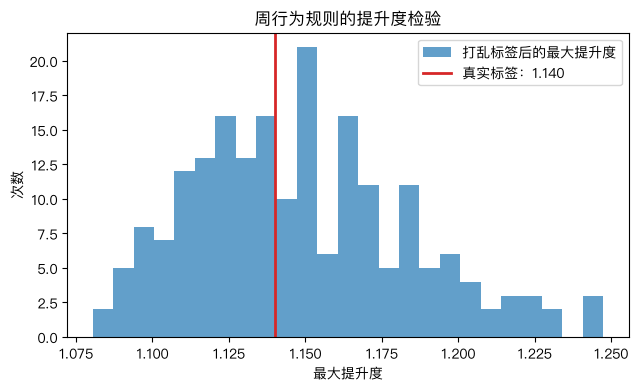

In [19]:
fi_x = apriori(onehot.drop(columns=['挂科', '不挂科']), min_support=MIN_SUPPORT, use_colnames=True, max_len=3)
masks = [onehot[list(s)].all(axis=1).to_numpy() for s in fi_x['itemsets']]
y = onehot['挂科'].to_numpy()

def max_lift(yv):
    base = yv.mean()
    best = 0
    for m_ in masks:
        sup = (m_ & yv).mean()
        if sup >= MIN_SUPPORT:
            best = max(best, (sup / m_.mean()) / base)
    return best

rng = np.random.default_rng(42)
obs = max_lift(y)
null = np.array([max_lift(rng.permutation(y)) for _ in range(200)])
print(f'真实标签下的最大提升度 {obs:.3f}；打乱标签 200 次，最大提升度的中位数 {np.median(null):.3f}，95% 分位数 {np.quantile(null, 0.95):.3f}')
print(f'打乱后仍不低于真实值的比例：{(null >= obs).mean():.2f}')

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.hist(null, bins=25, color='C0', alpha=0.7, label='打乱标签后的最大提升度')
ax.axvline(obs, color='C3', lw=2, label=f'真实标签：{obs:.3f}')
ax.set_xlabel('最大提升度')
ax.set_ylabel('次数')
ax.set_title('周行为规则的提升度检验')
ax.legend()
plt.tight_layout()
plt.show()

### 5.3 补充：加入主表特征

只用周行为时找不到可靠规则。为了检查 Apriori 本身能否挖出规则，再把主表中的掌握率、期中成绩、线上作业分、直播缺勤数和刷课标记加进事务数据集。

In [20]:
items2 = items.copy()
items2['掌握率'] = tertile(clean.loc[feat.index, 'knowledge_master_rate'], '掌握率')
items2['期中'] = tertile(clean.loc[feat.index, 'mid_score'], '期中')
items2['作业'] = tertile(clean.loc[feat.index, 'homework_online_score'], '作业')
items2['缺勤'] = tertile(clean.loc[feat.index, 'live_absent_num'], '缺勤')
items2['刷课'] = np.where(clean.loc[feat.index, 'brush_flag'], '刷课嫌疑', '非刷课')
onehot2 = pd.get_dummies(items2, prefix='', prefix_sep='').astype(bool)
rules_fail = mine(onehot2, '挂科')
rules_pass = mine(onehot2, '不挂科')
print(f"后件为'挂科'：{len(rules_fail)} 条，最大提升度 {rules_fail['lift'].max():.3f}")
print(f"后件为'不挂科'：{len(rules_pass)} 条，最大提升度 {rules_pass['lift'].max():.3f}")
rules_fail[['前件', 'support', 'confidence', 'lift']].head(8).round(3)

后件为'挂科'：970 条，最大提升度 1.501
后件为'不挂科'：115 条，最大提升度 2.457


,前件,support,confidence,lift
1854,掌握率高 + 缺勤低,0.101,0.976,1.501
8005,掌握率高 + 缺勤低 + 非刷课,0.097,0.975,1.500
4101,互动次数低 + 小测分数低 + 掌握率高,0.057,0.971,1.495
7175,掌握率高 + 缺勤低 + 视频平稳,0.083,0.971,1.494
7605,小测平稳 + 掌握率高 + 缺勤低,0.082,0.971,1.493
1852,作业高 + 掌握率高,0.100,0.968,1.489
7998,作业高 + 掌握率高 + 非刷课,0.096,0.966,1.487
7987,掌握率高 + 期中高 + 非刷课,0.108,0.963,1.481


In [21]:
rules_pass[['前件', 'support', 'confidence', 'lift']].head(8).round(3)

,前件,support,confidence,lift
7069,掌握率低 + 缺勤高 + 视频平稳,0.072,0.860,2.457
7502,小测平稳 + 掌握率低 + 缺勤高,0.071,0.850,2.429
7937,掌握率低 + 缺勤高 + 非刷课,0.075,0.849,2.426
1811,掌握率低 + 缺勤高,0.080,0.835,2.385
7924,作业低 + 掌握率低 + 非刷课,0.087,0.806,2.303
7909,掌握率低 + 期中低 + 非刷课,0.086,0.798,2.281
1800,掌握率低 + 期中低,0.088,0.797,2.277
1806,作业低 + 掌握率低,0.091,0.796,2.273


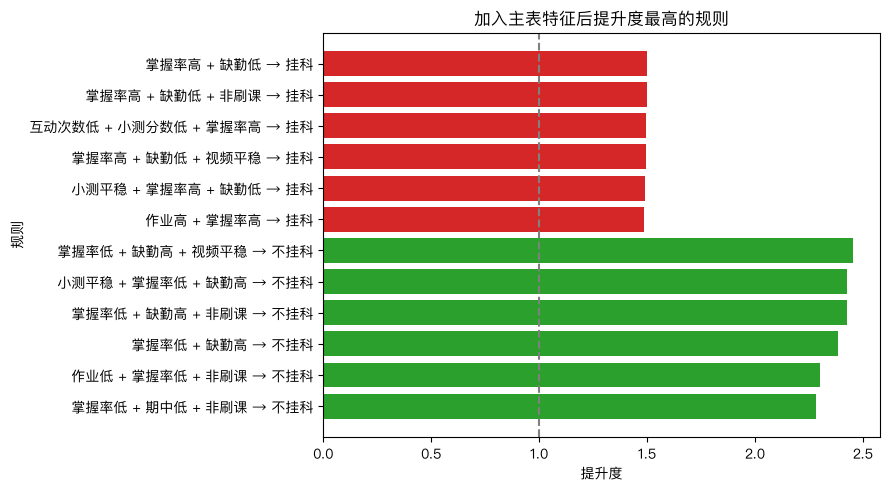

In [22]:
top = pd.concat([rules_fail.head(6).assign(后件='挂科'), rules_pass.head(6).assign(后件='不挂科')])
fig, ax = plt.subplots(figsize=(9, 5))
colors = ['C3' if t == '挂科' else 'C2' for t in top['后件']]
ax.barh(top['前件'] + ' → ' + top['后件'], top['lift'], color=colors)
ax.axvline(1, color='gray', ls='--')
ax.invert_yaxis()
ax.set_xlabel('提升度')
ax.set_ylabel('规则')
ax.set_title('加入主表特征后提升度最高的规则')
plt.tight_layout()
plt.show()

加入主表特征后，规则立刻变得很强，但方向违反常识："掌握率高、期中高、作业高"指向挂科，"掌握率低、缺勤多"指向不挂科。这正是第 1.2 节发现的标签方向问题：Apriori 如实挖出了生成脚本中的关系。周行为与挂科之间没有规则，同样是因为周表的生成过程完全没有用到挂科标签。

## 6. 主要数字汇总

In [23]:
summary = {
    '挂科率': round(feat['fail_label'].mean(), 3),
    '断崖学生占比': round(feat['断崖'].mean(), 3),
    'K=2 轮廓系数': round(sil[0], 3),
    'K=3 轮廓系数': round(sil[1], 3),
    'K=2 各簇挂科率': tab2['挂科率'].round(3).tolist(),
    'K=2 卡方 p 值': round(p2, 3),
    'K=3 各簇挂科率': tab3['挂科率'].round(3).tolist(),
    'K=3 卡方 p 值': round(p3, 3),
    '周行为规则最大提升度': round(obs, 3),
    '打乱标签后最大提升度 95% 分位': round(float(np.quantile(null, 0.95)), 3),
    '加入主表后"挂科"规则最大提升度': round(rules_fail['lift'].max(), 3),
    '加入主表后"不挂科"规则最大提升度': round(rules_pass['lift'].max(), 3),
}
pd.Series(summary).to_frame('值')

,值
挂科率,0.65
断崖学生占比,0.158
K=2 轮廓系数,0.547
K=3 轮廓系数,0.174
K=2 各簇挂科率,"[0.665, 0.647]"
K=2 卡方 p 值,0.693
K=3 各簇挂科率,"[0.665, 0.662, 0.631]"
K=3 卡方 p 值,0.516
周行为规则最大提升度,1.14
打乱标签后最大提升度 95% 分位,1.215
